# Task 3 — Reproducible Benchmark Analysis

**Research repository:** `zhadritto/ai-phishing-literature-review`

This notebook runs the repository's technical benchmark in Google Colab, processes the JSONL measurements, excludes warm-up runs from latency statistics, calculates median, percentiles and participant-independent run-level bootstrap confidence intervals, tracks execution errors, and exports the two required figures.

**Important distinction:** this notebook analyzes the performance of the Python data-processing pipeline. It does not analyze student survey accuracy. Survey analysis is a separate research workflow.

Run the notebook from top to bottom using **Runtime → Run all**. The benchmark uses synthetic workload records only; they are not student responses and must not be described as survey findings.

In [1]:
# Cell 1 — Install the one additional configuration dependency
%pip -q install "PyYAML>=6,<7"

In [2]:
# Cell 2 — Set up the repository workspace and download the committed source files
from pathlib import Path
import sys
import urllib.request

REPOSITORY = "zhadritto/ai-phishing-literature-review"
BRANCH = "main"
BASE_URL = f"https://raw.githubusercontent.com/{REPOSITORY}/{BRANCH}/"

WORKSPACE = Path("/content/ai-phishing-literature-review")
FILES_TO_DOWNLOAD = [
    "config/benchmark_config.yaml",
    "src/benchmark.py",
    "src/process_data.py",
    "src/visualize.py",
]

for relative_path in FILES_TO_DOWNLOAD:
    destination = WORKSPACE / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)
    url = BASE_URL + relative_path
    try:
        with urllib.request.urlopen(url, timeout=30) as response:
            content = response.read()
        destination.write_bytes(content)
        print(f"Downloaded: {relative_path}")
    except Exception as exc:
        raise RuntimeError(
            f"Could not download {relative_path} from GitHub. "
            "Check that the file has been committed to the main branch. "
            f"Original error: {exc}"
        ) from exc

if str(WORKSPACE) not in sys.path:
    sys.path.insert(0, str(WORKSPACE))

print("\\nWorkspace:", WORKSPACE)
print("Repository files are ready.")

Downloaded: config/benchmark_config.yaml
Downloaded: src/benchmark.py
Downloaded: src/process_data.py
Downloaded: src/visualize.py
\nWorkspace: /content/ai-phishing-literature-review
Repository files are ready.


## 1. Data collection and measurement

The next cell executes the committed `src/benchmark.py`. It creates a synthetic workload at four input sizes and compares two implementations of the same aggregation task (`baseline` and `proposed`). Each method receives five warm-up runs and thirty evaluation runs per input size.

The target function is timed with `time.perf_counter_ns()`. JSONL serialization and file writing happen after the measured interval. Failed runs remain in the logs and are counted by the error-rate guardrail.

In [3]:
# Cell 3 — Run the benchmark and create the raw JSONL log
from src import benchmark

benchmark.main()

RAW_LOG = WORKSPACE / "data/raw/test_run.jsonl"
assert RAW_LOG.exists(), "Benchmark did not create the JSONL file."
print("\\nRaw JSONL file:", RAW_LOG)
print("Raw log size (bytes):", RAW_LOG.stat().st_size)

DATA PROCESSING PERFORMANCE BENCHMARK
Run ID: 6fa201ad2732
Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
CPU count: 2

Validating implementations...
Baseline and proposed results match.

Processing load size: 100
Warm-up and evaluation completed.

Processing load size: 1000
Warm-up and evaluation completed.

Processing load size: 5000
Warm-up and evaluation completed.

Processing load size: 10000
Warm-up and evaluation completed.

JSONL logs saved to:
/content/ai-phishing-literature-review/data/raw/test_run.jsonl

FINAL BENCHMARK SUMMARY
Total runs: 280
Warm-up runs: 40
Evaluation runs: 240
Successful runs: 280
Failed runs: 0
Execution error rate: 0.00%
All benchmark executions completed successfully.
\nRaw JSONL file: /content/ai-phishing-literature-review/data/raw/test_run.jsonl
Raw log size (bytes): 148940


## 2. Data ingestion and validation

Load the JSONL log and validate the required fields. Warm-up rows are retained in the raw file for transparency, but they will not contribute to latency summaries.

In [4]:
# Cell 4 — Load and validate raw JSONL measurements
from src import process_data

config = process_data.load_config()
raw_data = process_data.load_jsonl(config["raw_file"])
validated_data = process_data.validate_data(raw_data)

print("Total raw records:", len(validated_data))
print("\\nRecords by phase:")
display(validated_data["phase"].value_counts().rename_axis("phase").to_frame("records"))
print("\\nRecords by method and phase:")
display(
    validated_data.groupby(["method", "phase"]).size()
    .rename("records").reset_index()
)

Total raw records: 280
\nRecords by phase:


,records
phase,
benchmark,240
warmup,40


\nRecords by method and phase:


,method,phase,records
0,baseline,benchmark,120
1,baseline,warmup,20
2,proposed,benchmark,120
3,proposed,warmup,20


In [5]:
# Cell 5 — Explicitly separate warm-up and evaluation runs
warmup_data = validated_data[validated_data["phase"] == "warmup"].copy()
evaluation_data = validated_data[validated_data["phase"] == "benchmark"].copy()

assert not evaluation_data.empty, "No evaluation measurements were found."
assert (evaluation_data["phase"] == "benchmark").all()
assert not (evaluation_data["phase"] == "warmup").any()

print("Warm-up records excluded from statistics:", len(warmup_data))
print("Evaluation records used for statistics:", len(evaluation_data))
print("\\nEvaluation runs by method and input size:")
display(
    evaluation_data.groupby(["method", "load_size"])
    .size().rename("evaluation_runs").reset_index()
)

Warm-up records excluded from statistics: 40
Evaluation records used for statistics: 240
\nEvaluation runs by method and input size:


,method,load_size,evaluation_runs
0,baseline,100,30
1,baseline,1000,30
2,baseline,5000,30
3,baseline,10000,30
4,proposed,100,30
5,proposed,1000,30
6,proposed,5000,30
7,proposed,10000,30


## 3. Statistical aggregation

For each method and input size, calculate mean, standard deviation, median, p25, p75, p95 and p99. The 95% confidence intervals are percentile-bootstrap intervals. Failed execution attempts are excluded from latency distribution estimates but remain in the error-rate denominator and in a separate error report.

Because the benchmark compares run-level execution times, the bootstrap resamples successful evaluation runs within each method/load condition. This is distinct from the participant-level bootstrap used for the student survey.

In [6]:

# Cell 6 — Calculate and save benchmark results

from src import process_data

summary = process_data.calculate_summary(
    validated_data,
    config
)

speedup = process_data.calculate_speedup(
    validated_data,
    config
)

error_summary = process_data.create_error_summary(
    validated_data
)

# Save all CSV files before visualization.
process_data.save_outputs(
    summary,
    speedup,
    error_summary,
    config
)

print("Benchmark summary:")
display(summary)

print("Speedup summary:")
display(speedup)

print("Error summary:")

if error_summary.empty:
    print("No failed evaluation runs.")
else:
    display(error_summary)



OUTPUT FILES
/content/ai-phishing-literature-review/data/processed/metrics_summary.csv
/content/ai-phishing-literature-review/data/processed/speedup_summary.csv
/content/ai-phishing-literature-review/data/processed/benchmark_error_summary.csv
Benchmark summary:


,method,load_size,evaluation_attempts,expected_evaluation_runs,successful_runs,failed_runs,run_count_complete,success_rate,error_rate,missing_input_rate,...,p25_ms,p75_ms,p95_ms,p99_ms,mean_ci_lower_ms,mean_ci_upper_ms,median_ci_lower_ms,median_ci_upper_ms,latency_sample_count,warmup_runs_excluded
0,baseline,100,30,30,30,0,True,1.0,0.0,0.01,...,0.613116,0.726336,1.170237,1.180443,0.681143,0.810349,0.628030,0.715070,30,5
1,baseline,1000,30,30,30,0,True,1.0,0.0,0.01,...,2.651342,4.546249,6.607871,8.626228,3.663457,4.724491,4.236711,4.520836,30,5
2,baseline,5000,30,30,30,0,True,1.0,0.0,0.01,...,21.844874,37.349095,53.737882,66.267376,26.339943,34.839031,22.357382,33.244174,30,5
3,baseline,10000,30,30,30,0,True,1.0,0.0,0.01,...,20.688684,21.347576,26.826121,63.413532,20.996216,27.329231,20.752953,21.128675,30,5
4,proposed,100,30,30,30,0,True,1.0,0.0,0.01,...,4.375212,6.670621,7.587211,13.408143,4.856785,6.418297,4.388753,5.016112,30,5
5,proposed,1000,30,30,30,0,True,1.0,0.0,0.01,...,8.899836,12.269407,20.523634,24.777983,10.006450,13.319850,10.657860,11.793402,30,5
6,proposed,5000,30,30,30,0,True,1.0,0.0,0.01,...,26.136462,39.585202,52.349250,66.813601,31.570051,39.015620,27.929403,37.565720,30,5
7,proposed,10000,30,30,30,0,True,1.0,0.0,0.01,...,22.219254,23.582597,25.696260,33.037440,22.633962,24.471930,22.320965,23.191016,30,5


Speedup summary:


,load_size,paired_successful_runs,median_speedup,ci_lower,ci_upper
0,100,30,0.147818,0.138300,0.157893
1,1000,30,0.390118,0.374947,0.408029
2,5000,30,0.827602,0.638325,0.933830
3,10000,30,0.926205,0.908085,0.941588


Error summary:
No failed evaluation runs.


In [7]:
# Cell 7 — Check expected experiment completeness
expected_methods = config["methods"]
expected_loads = config["load_sizes"]
expected_repetitions = config["expected_evaluation_runs"]

expected_groups = len(expected_methods) * len(expected_loads)
assert len(summary) == expected_groups, (
    f"Expected {expected_groups} method/load groups, found {len(summary)}"
)

incomplete = summary[~summary["run_count_complete"]]
if not incomplete.empty:
    print("WARNING: Some method/load groups do not have the expected number of evaluation attempts:")
    display(incomplete[["method", "load_size", "evaluation_attempts", "expected_evaluation_runs"]])
else:
    print(f"All {expected_groups} method/load groups contain {expected_repetitions} evaluation attempts.")

print("\\nOverall failed evaluation attempts:", int((~evaluation_data["success"]).sum()))
print("Overall evaluation error rate (%):", round((~evaluation_data["success"]).mean() * 100, 3))

All 8 method/load groups contain 30 evaluation attempts.
\nOverall failed evaluation attempts: 0
Overall evaluation error rate (%): 0.0


## 4. Baseline versus proposed method

Speedup is defined as `baseline latency / proposed latency`. A value above 1 indicates that the proposed implementation was faster for that paired repetition. Interpret the result together with the error rate and confidence interval; do not report a speedup if the paired successful-run count is insufficient.

In [8]:
# Cell 8 — Present a compact comparison table
comparison_columns = [
    "method", "load_size", "successful_runs", "failed_runs",
    "error_rate", "mean_ms", "std_ms", "median_ms",
    "p25_ms", "p75_ms", "p95_ms", "p99_ms",
    "median_ci_lower_ms", "median_ci_upper_ms"
]

comparison_table = summary[comparison_columns].copy()
comparison_table["error_rate_percent"] = comparison_table["error_rate"] * 100
comparison_table["median_meaning"] = comparison_table.apply(
    lambda row: f"{row['median_ms']:.3f} ms ({row['p25_ms']:.3f}–{row['p75_ms']:.3f})",
    axis=1
)
display(comparison_table)

,method,load_size,successful_runs,failed_runs,error_rate,mean_ms,std_ms,median_ms,p25_ms,p75_ms,p95_ms,p99_ms,median_ci_lower_ms,median_ci_upper_ms,error_rate_percent,median_meaning
0,baseline,100,30,0,0.0,0.740917,0.185351,0.689884,0.613116,0.726336,1.170237,1.180443,0.628030,0.715070,0.0,0.690 ms (0.613–0.726)
1,baseline,1000,30,0,0.0,4.161248,1.486218,4.439098,2.651342,4.546249,6.607871,8.626228,4.236711,4.520836,0.0,4.439 ms (2.651–4.546)
2,baseline,5000,30,0,0.0,30.378469,12.438780,23.505694,21.844874,37.349095,53.737882,66.267376,22.357382,33.244174,0.0,23.506 ms (21.845–37.349)
3,baseline,10000,30,0,0.0,23.257662,10.336169,20.876266,20.688684,21.347576,26.826121,63.413532,20.752953,21.128675,0.0,20.876 ms (20.689–21.348)
4,proposed,100,30,0,0.0,5.511571,2.280332,4.446016,4.375212,6.670621,7.587211,13.408143,4.388753,5.016112,0.0,4.446 ms (4.375–6.671)
5,proposed,1000,30,0,0.0,11.566415,4.688013,11.110180,8.899836,12.269407,20.523634,24.777983,10.657860,11.793402,0.0,11.110 ms (8.900–12.269)
6,proposed,5000,30,0,0.0,35.063345,10.566011,34.620076,26.136462,39.585202,52.349250,66.813601,27.929403,37.565720,0.0,34.620 ms (26.136–39.585)
7,proposed,10000,30,0,0.0,23.364768,2.638684,22.519650,22.219254,23.582597,25.696260,33.037440,22.320965,23.191016,0.0,22.520 ms (22.219–23.583)


## 5. Scientific visualization and export

Both figures are exported as vector PDF and 300-DPI PNG files. Figure 1 shows median processing latency with a 95% bootstrap confidence interval. Figure 2 shows the latency distribution, including the median, interquartile range, outliers, and a mean marker with a 95% bootstrap interval.

In [9]:
# Cell 9 — Generate and save the two required figures
from src import visualize

visualize.main()

FIGURES_DIR = WORKSPACE / "reports/figures"
required_figures = [
    "fig1_latency_vs_load.png",
    "fig1_latency_vs_load.pdf",
    "fig2_distribution_boxplot.png",
    "fig2_distribution_boxplot.pdf",
]

for name in required_figures:
    path = FIGURES_DIR / name
    assert path.exists() and path.stat().st_size > 0, f"Missing or empty figure: {name}"
    print(f"Created: {name} ({path.stat().st_size:,} bytes)")

SCIENTIFIC VISUALIZATION

Generating Figure 1...
Figure 1 exported.

Generating Figure 2...
Figure 2 exported.

All figures successfully generated.
Output directory:
/content/ai-phishing-literature-review/reports/figures
Created: fig1_latency_vs_load.png (366,151 bytes)
Created: fig1_latency_vs_load.pdf (22,245 bytes)
Created: fig2_distribution_boxplot.png (167,189 bytes)
Created: fig2_distribution_boxplot.pdf (27,541 bytes)


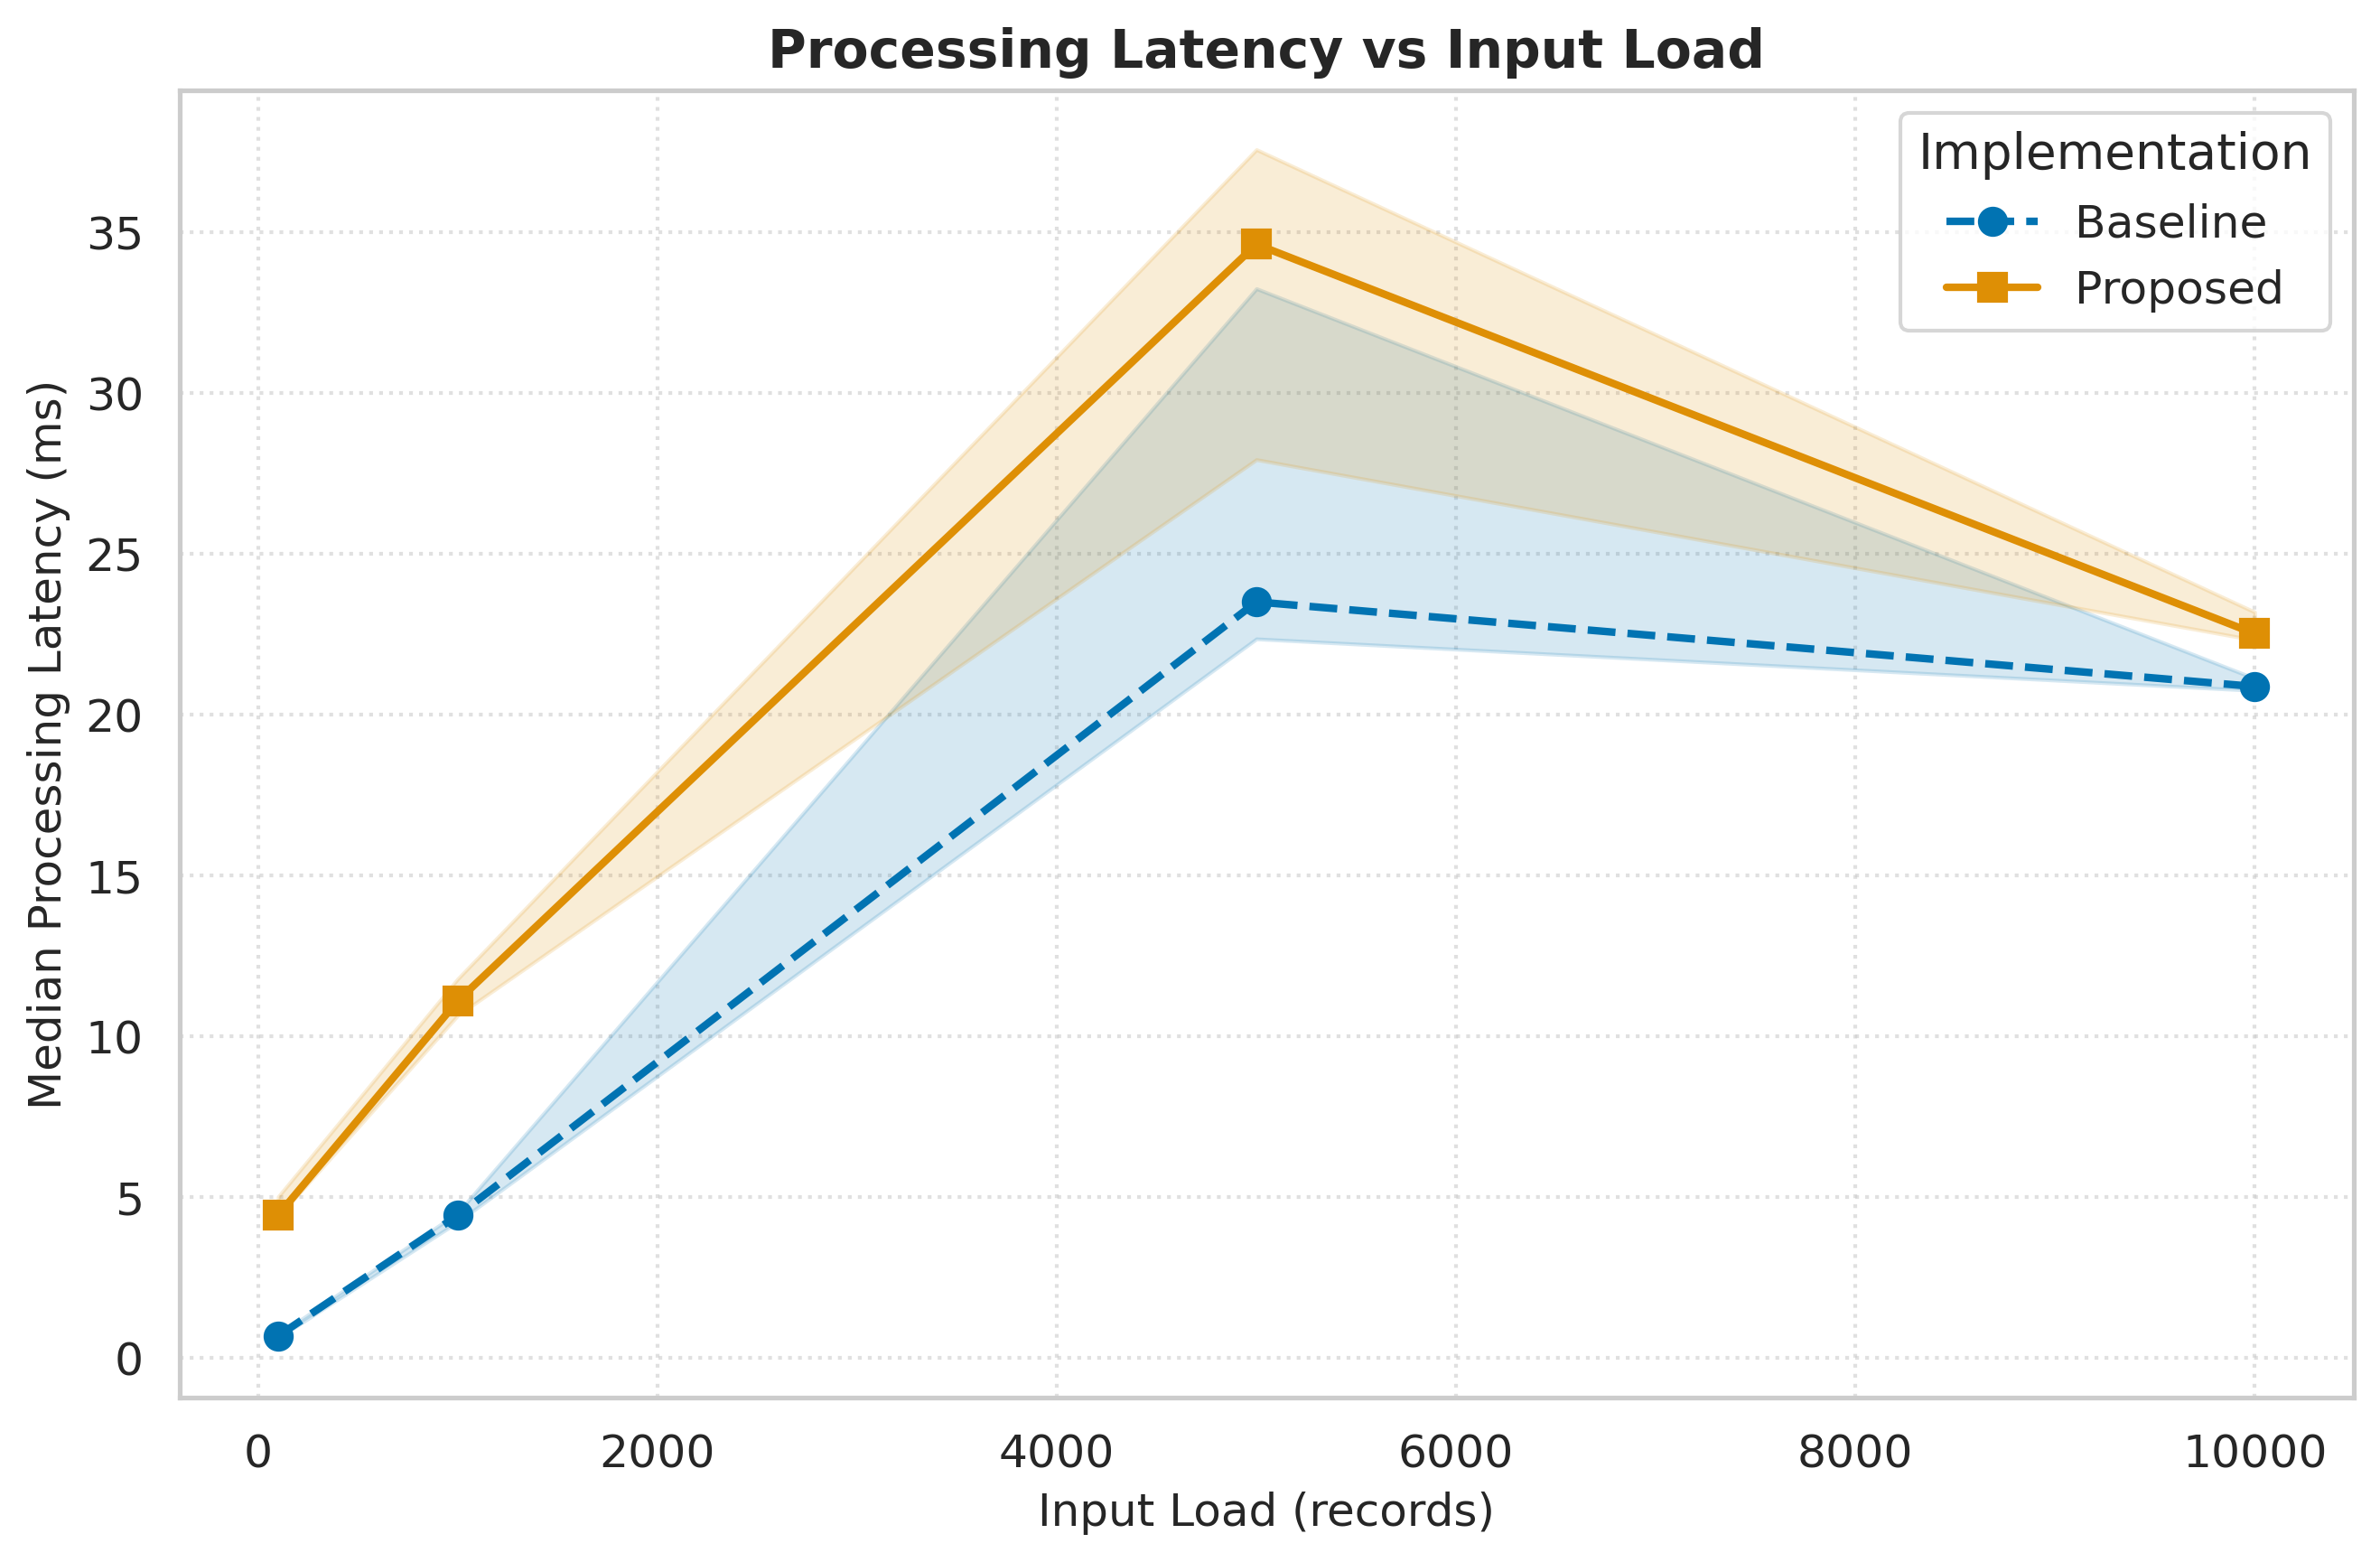

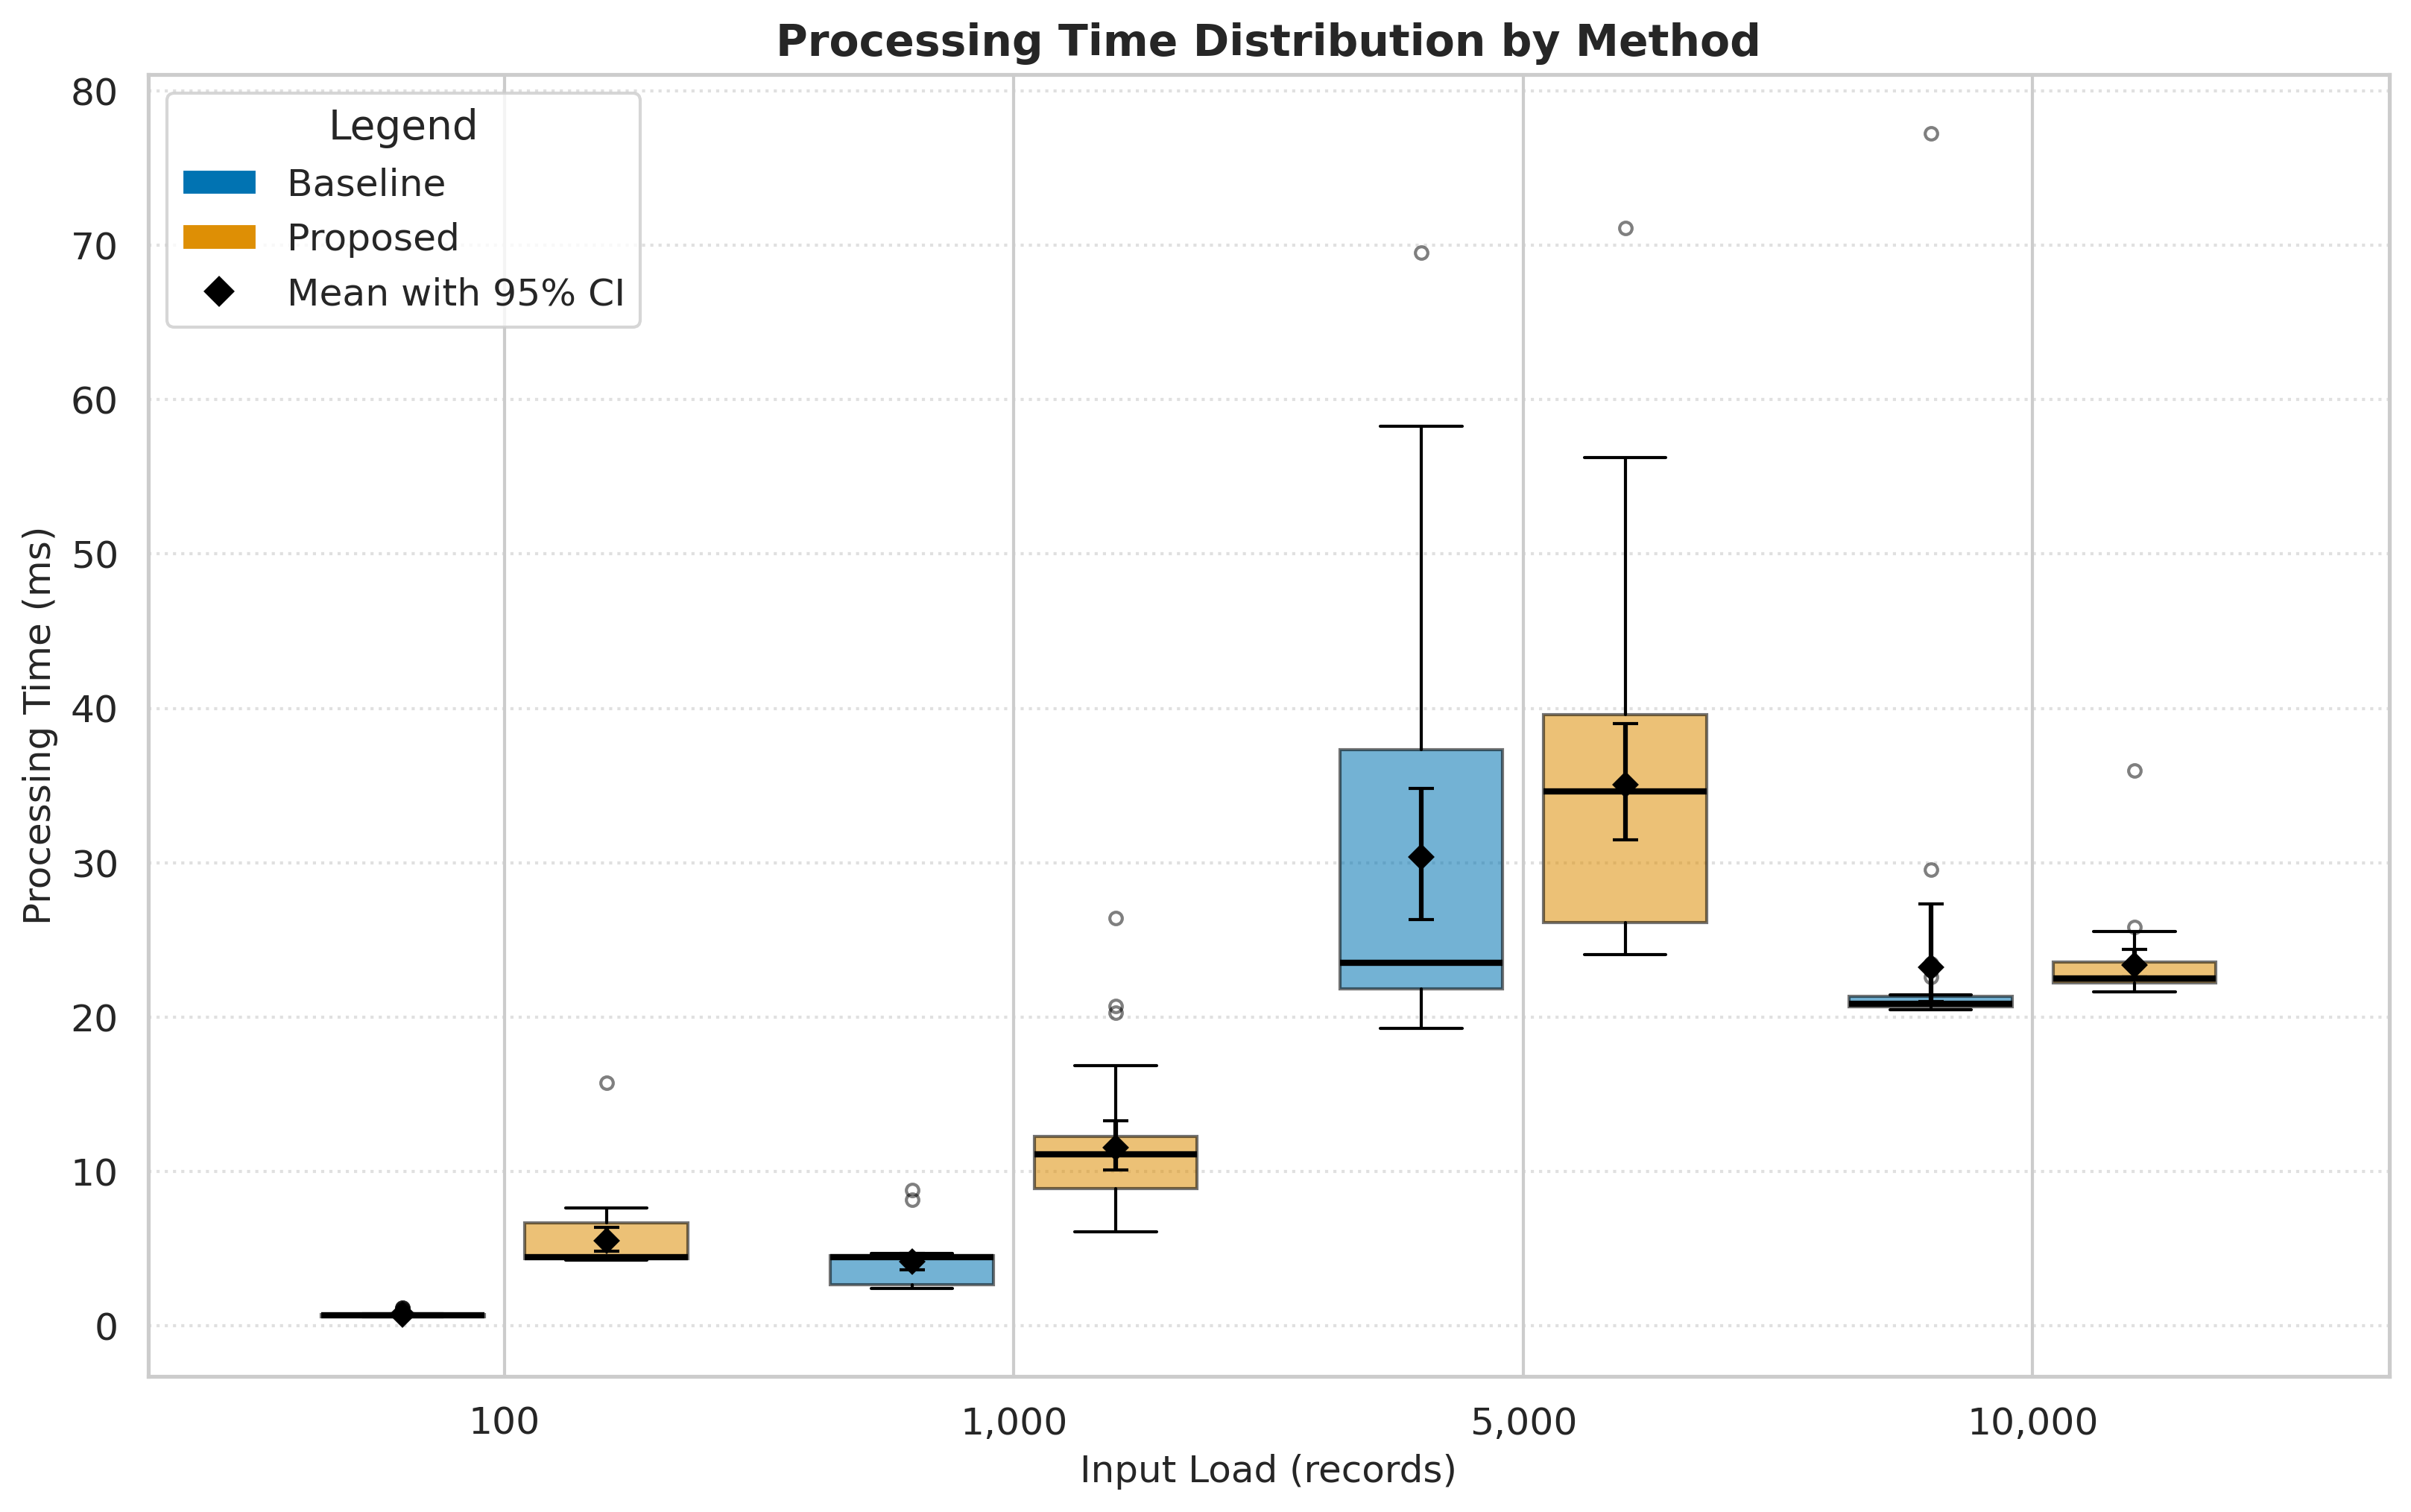

In [10]:
# Cell 10 — Display the generated PNG figures
from IPython.display import display, Image

display(Image(filename=str(FIGURES_DIR / "fig1_latency_vs_load.png")))
display(Image(filename=str(FIGURES_DIR / "fig2_distribution_boxplot.png")))

## 6. Interpretation and reporting

Use the generated tables and figures to describe the measured behavior. Do not assume that `proposed` is faster: state what the measurements show. Report latency in milliseconds, input size in records, uncertainty intervals, and error rates. Mention the benchmark environment (Python version, operating system, CPU information) stored in the raw JSONL records.

The benchmark uses synthetic records to compare two local data-processing implementations. These measurements do not describe email-delivery latency, phishing detection effectiveness, or student behavior.

In [11]:
# Cell 11 — Show environment metadata recorded by the benchmark
metadata_columns = [
    column for column in [
        "python_version", "platform", "machine",
        "processor", "cpu_count", "pandas_version", "numpy_version"
    ]
    if column in validated_data.columns
]

environment = validated_data[metadata_columns].drop_duplicates()
display(environment)

,python_version,platform,machine,processor,cpu_count,pandas_version,numpy_version
0,3.13.18,Linux-6.6.159+-x86_64-with-glibc2.39,x86_64,x86_64,2,2.2.3,2.4.6


In [12]:
# Cell 12 — Export all benchmark artifacts into one ZIP for GitHub upload
import zipfile

EXPORT_DIR = Path("/content/task3_benchmark_outputs")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Re-save processed tables to the paths expected by the assignment.
process_data.save_outputs(summary, speedup, error_summary, config)

artifacts = [
    config["raw_file"],
    config["summary_file"],
    config["speedup_file"],
    config["error_file"],
    FIGURES_DIR / "fig1_latency_vs_load.png",
    FIGURES_DIR / "fig1_latency_vs_load.pdf",
    FIGURES_DIR / "fig2_distribution_boxplot.png",
    FIGURES_DIR / "fig2_distribution_boxplot.pdf",
]

zip_path = EXPORT_DIR / "task3_benchmark_outputs.zip"

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in artifacts:
        if path.exists():
            archive.write(path, arcname=str(path.relative_to(WORKSPACE)))
        else:
            print("Not included because it does not exist:", path)

print("Export package created:", zip_path)
print("Package size:", f"{zip_path.stat().st_size:,} bytes")


OUTPUT FILES
/content/ai-phishing-literature-review/data/processed/metrics_summary.csv
/content/ai-phishing-literature-review/data/processed/speedup_summary.csv
/content/ai-phishing-literature-review/data/processed/benchmark_error_summary.csv
Export package created: /content/task3_benchmark_outputs/task3_benchmark_outputs.zip
Package size: 496,690 bytes


In [13]:
# Cell 13 — Download the benchmark package to your computer
from google.colab import files
files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Final reproducibility checklist

- [ ] Notebook was run from the first cell to the last without errors.
- [ ] Raw JSONL contains both `warmup` and `benchmark` records.
- [ ] Warm-up records are excluded from latency summaries.
- [ ] Mean, SD, median, p25, p75, p95 and p99 are reported.
- [ ] 95% bootstrap confidence intervals are reported.
- [ ] Failed runs are counted in the error-rate guardrail.
- [ ] Baseline and proposed outputs are validated as equivalent.
- [ ] Both figures exist in PDF and 300-DPI PNG formats.
- [ ] Raw logs and aggregate outputs are clearly identified as synthetic pipeline benchmark data, not student survey results.

**Submission note:** Save this executed notebook to the repository as `notebooks/01_data_analysis.ipynb`. Upload the exported benchmark artifacts to their matching repository folders. Keep the original Google Forms export and participant-level survey data private.